# Part 0. Data loading

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dvaser/online-retail-ii")

print("Path to dataset files:", path)

Path to dataset files: /Users/lizardking/.cache/kagglehub/datasets/dvaser/online-retail-ii/versions/1


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

In [3]:
file_path = os.path.join(path, "online_retail_II.xlsx")

sheets = pd.read_excel(file_path, sheet_name=["Year 2009-2010", "Year 2010-2011"])

In [4]:
type(sheets)

dict

In [5]:
sheets.keys()

dict_keys(['Year 2009-2010', 'Year 2010-2011'])

In [6]:
sheet1 = sheets["Year 2009-2010"]
sheet2 = sheets["Year 2010-2011"]

In [7]:
sheet1.shape

(525461, 8)

In [8]:
sheet2.shape

(541910, 8)

In [9]:
sheet1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


## Overlap between the two sheets
The first sheet ends on 9 Dec 2010, while the second one starts on 1 Dec 2010, so 1-9 Dec 2010 appears in both sheets. We need to check whether these are the same transactions.

In [10]:
sheet1['InvoiceDate'].min()

Timestamp('2009-12-01 07:45:00')

In [11]:
sheet1['InvoiceDate'].max()

Timestamp('2010-12-09 20:01:00')

In [12]:
sheet2['InvoiceDate'].min()

Timestamp('2010-12-01 08:26:00')

In [13]:
sheet2['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

In [14]:
overlap1= sheet1[sheet1['InvoiceDate'] >= '2010-12-01']

In [15]:
overlap2= sheet2[sheet2['InvoiceDate'] < '2010-12-10']

In [16]:
len(overlap1)

22523

In [17]:
len(overlap2)

22523

In [18]:
overlap1.nunique()

Invoice        1088
StockCode      2481
Description    2419
Quantity        165
InvoiceDate     921
Price           216
Customer ID     622
Country          18
dtype: int64

In [19]:
overlap2.nunique()

Invoice        1088
StockCode      2481
Description    2419
Quantity        165
InvoiceDate     921
Price           216
Customer ID     622
Country          18
dtype: int64

In [20]:
len(set(overlap1["Invoice"]) & set(overlap2["Invoice"]))

1088

In [21]:
overlap1.reset_index(drop=True).equals(overlap2.reset_index(drop=True))

False

In [22]:
cols = list(overlap1.columns)

overlap1.sort_values(by=cols).reset_index(drop=True).equals(overlap2.sort_values(by=cols).reset_index(drop=True))

True

**Conclusion:** 1-9 Dec 2010 (22,523 rows, 1,088 invoices) is exported twice. To avoid double counting, the first sheet is cut before 1 Dec 2010 and the second sheet is taken fully: 525,461 + 541,910 − 22,523 = **1,044,848 rows**.

In [23]:
df = pd.concat([sheet1[sheet1['InvoiceDate'] < '2010-12-01'], sheet2], ignore_index=True)

In [24]:
df["Invoice"] = df["Invoice"].astype("string")

In [25]:
df["StockCode"] = df["StockCode"].astype("string")

In [26]:
df["Description"] = df["Description"].astype("string")

Invoice, StockCode and Description contain both numbers and text, so they are converted to the `string` type (it keeps missing values as missing). The result is saved to parquet, so the slow Excel file doesn't need to be read again.

In [27]:
df.to_parquet('online_retail.parquet', index=False)

In [28]:
check = pd.read_parquet("online_retail.parquet")

In [29]:
check.shape

(1044848, 8)

In [30]:
check.dtypes

Invoice        string[python]
StockCode      string[python]
Description    string[python]
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

In [31]:
check.isna().sum()

Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235287
Country             0
dtype: int64

In [32]:
check.equals(df)

True

In [33]:
df = pd.read_parquet("online_retail.parquet")

# Part 1. Data quality

### 1.1 What is one row?

In [34]:
len(df)

1044848

In [35]:
df["Invoice"].nunique()

53628

In [36]:
df[df["Invoice"] == "489435"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom
10,489435,22195,HEART MEASURING SPOONS LARGE,24,2009-12-01 07:46:00,1.65,13085.0,United Kingdom
11,489435,22353,LUNCHBOX WITH CUTLERY FAIRY CAKES,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom


In [37]:
df.groupby("Invoice").size().describe()

count    53628.000000
mean        19.483255
std         38.447694
min          1.000000
25%          1.000000
50%          9.000000
75%         23.000000
max       1114.000000
dtype: float64

One row = one product line in an invoice. Customer, country and date are the same for all rows of an invoice, while the product, quantity and price differ.

There are 53,628 invoices, ~19.5 rows per invoice on average, but the median is only 9: the distribution is right-skewed because of a few very big (wholesale) orders. A quarter of the invoices have only one row.

In [38]:
lines_per_invoice = df.groupby("Invoice").size()
single_line = lines_per_invoice[lines_per_invoice == 1]
len(single_line)

13570

In [39]:
single_line.index.str.startswith("C").mean()

np.float64(0.34576271186440677)

In [40]:
single_line_not_c = single_line.index[~single_line.index.str.startswith("C")]
len(single_line_not_c)

8878

In [41]:
df[df["Invoice"].isin(single_line_not_c)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.0,USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.0,Belgium
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1043327,581479,22087,PAPER BUNTING WHITE LACE,10,2011-12-09 09:00:00,2.95,17364.0,United Kingdom
1043359,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
1043380,581487,21137,BLACK RECORD COVER FRAME,120,2011-12-09 09:44:00,3.39,15694.0,United Kingdom
1043388,581491,23571,TRADITIONAL NAUGHTS & CROSSES,12,2011-12-09 10:02:00,1.65,12433.0,Norway


Among the invoices with only one row, 34.6% are cancellations. The other single-row invoices are mostly not regular purchases: postage, stock adjustments with zero price and no customer ("short", "mixed", "check") and similar records.

### 1.2 Rows without Customer ID

In [42]:
null_customer = df[df["Customer ID"].isna()]

In [43]:
null_customer['Invoice'].str.startswith('C').mean()

np.float64(0.003055842439233787)

In [44]:
print("price <= 0:", (null_customer["Price"] <= 0).mean())
print("quantity < 0:", (null_customer["Quantity"] < 0).mean())

price <= 0: 0.025326516127112845
quantity < 0: 0.017472278536425728


In [45]:
revenue=(df['Price']*df['Quantity']).sum()

The variable `revenue` is the net revenue: it includes cancellations (negative quantities) and other adjustments.

In [46]:
rev_null_customer = (null_customer['Price']*null_customer['Quantity']).sum()
share_null_customer = (rev_null_customer/revenue *100)
print(share_null_customer,'%')

13.570202861290168 %


22.5% of the rows have no Customer ID, but only 0.3% of them are cancellations and ~2.5% have zero price. Together they generate 13.6% of the revenue, so these are mostly **regular sales without customer identification**. They are kept for the revenue analysis, but removed from the customer analysis (RFM, cohorts).

In [47]:
df["Customer ID"].nunique()

5942

In [48]:
df["Country"].nunique()

43

### 1.3 Invoice prefixes

In [49]:
df["Invoice"].str[0].value_counts()

Invoice
5    917188
4    108489
C     19165
A         6
Name: count, dtype: Int64

In [50]:
df[df["Invoice"].str.startswith("C")]["Invoice"].nunique()

8292

19,165 **rows** belong to cancellation invoices (starting with "C"), which is 8,292 cancelled **invoices**. There are also 6 invoices starting with "A":

In [51]:
a_letter = df[df["Invoice"].str.startswith("A")]
a_letter

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
802920,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
802921,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
802922,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


The invoices starting with "A" are **bad debt adjustments** ("Adjust bad debt"): accounting write-offs of money that customers didn't pay. They are not sales.

In [52]:
a_letter_revenue= (a_letter['Price']*a_letter['Quantity']).sum()
a_letter_revenue

np.float64(-147614.08)

The company wrote off uncollectible accounts receivable for **£147,614**.

In [53]:
share_a_letter_from_null_customer = (a_letter_revenue/rev_null_customer *100)
print(share_a_letter_from_null_customer,'%')

-5.752483460186878 %


The bad debt write-offs reduce the revenue of the rows without Customer ID by about 6%.

In [54]:
b_code = df[df["StockCode"].str.startswith("B")]
b_code

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
18410,C490943,BANK CHARGES,Bank Charges,-1,2009-12-08 14:08:00,15.00,16703.0,United Kingdom
18466,490948,BANK CHARGES,Bank Charges,1,2009-12-08 14:29:00,15.00,16805.0,United Kingdom
33435,C492206,BANK CHARGES,Bank Charges,-1,2009-12-15 16:32:00,848.43,NaN,United Kingdom
55948,C494438,BANK CHARGES,Bank Charges,-1,2010-01-14 12:15:00,767.99,NaN,United Kingdom
94431,498269,BANK CHARGES,Bank Charges,1,2010-02-17 15:03:00,15.00,16928.0,United Kingdom
...,...,...,...,...,...,...,...,...
943683,574546,BANK CHARGES,Bank Charges,1,2011-11-04 14:59:00,15.00,13651.0,United Kingdom
984090,C577342,BANK CHARGES,Bank Charges,-1,2011-11-18 15:11:00,490.06,NaN,United Kingdom
984091,C577343,BANK CHARGES,Bank Charges,-1,2011-11-18 15:13:00,27.21,NaN,United Kingdom
1009295,579137,BANK CHARGES,Bank Charges,1,2011-11-28 12:51:00,15.00,14704.0,United Kingdom


Stock codes starting with "B" are the bad debt code `B` and `BANK CHARGES` (bank fees). Both are service records, not products.

### 1.4 Negative quantities

In [55]:
neg_qty = df["Quantity"] < 0
not_cancel = ~df["Invoice"].str.startswith("C")
neg_qty_not_cancel = df[neg_qty & not_cancel]
len(neg_qty_not_cancel)

3393

In [56]:
neg_qty_not_cancel

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1038271,581210,23395,check,-26,2011-12-07 18:36:00,0.0,NaN,United Kingdom
1038273,581212,22578,lost,-1050,2011-12-07 18:38:00,0.0,NaN,United Kingdom
1038274,581213,22576,check,-30,2011-12-07 18:38:00,0.0,NaN,United Kingdom
1039848,581226,23090,missing,-338,2011-12-08 09:56:00,0.0,NaN,United Kingdom


In [57]:
(neg_qty_not_cancel["Price"] == 0).mean()

np.float64(1.0)

In [58]:
neg_qty_not_cancel["Customer ID"].isna().mean()

np.float64(1.0)

In [59]:
neg_qty_not_cancel["Description"].isna().mean()

np.float64(0.776009431181845)

In [60]:
len(neg_qty_not_cancel) / neg_qty.sum()

np.float64(0.1504189386886554)

**Findings:** of all rows with negative quantity, 85% belong to cancellation invoices (starting with "C"), i.e. customer returns.
The remaining 15% (3,393 rows) are warehouse stock write-offs: they always have price 0 and no customer, and descriptions like "damaged", "lost", "missing", "check" (78% have no description). They don't affect revenue and will be removed from sales and customer analysis.

### 1.5 Zero and negative prices

In [61]:
neg_price = df["Price"] < 0
pos_qty = df["Quantity"] > 0
neg_price.sum()

np.int64(5)

In [62]:
df[neg_price]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
802921,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
802922,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Negative prices appear only in the bad debt adjustments ("A" invoices): they always have quantity 1. One write-off in Aug 2011 was registered with a positive sign and then corrected with a negative one.

In [63]:
zero_price = df["Price"] == 0
(pos_qty & zero_price).sum()

np.int64(2631)

In [64]:
pos_qty_zero_price = df[pos_qty & zero_price]
pos_qty_zero_price

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
3161,489659,21350,<NA>,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,<NA>,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
5904,489861,DOT,DOTCOM POSTAGE,1,2009-12-02 14:50:00,0.0,NaN,United Kingdom
6378,489882,35751C,<NA>,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
1038272,581211,22142,check,14,2011-12-07 18:36:00,0.0,NaN,United Kingdom
1039919,581234,72817,<NA>,27,2011-12-08 10:33:00,0.0,NaN,United Kingdom
1041442,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08 13:58:00,0.0,NaN,United Kingdom
1041443,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08 13:58:00,0.0,NaN,United Kingdom


In [65]:
pos_qty_zero_price['Customer ID'].notna().mean()

np.float64(0.0266058532877233)

2,631 rows have zero price and positive quantity. 97% of them have no customer: these are stock adjustments (found items, re-counts), the mirror of the write-offs in 1.4. The remaining ~3% (70 rows) are products given to customers for free (gifts, samples or price errors) and test records. They don't affect revenue and are removed from the analysis.

### 1.6 Service stock codes

In [66]:
df["StockCode"].str.len().value_counts()

StockCode
5     912611
6     124965
4       2122
1       1684
3       1425
7       1370
2        278
12       200
8        126
9         67
Name: count, dtype: Int64

Regular products have 5 or 6 characters in the StockCode (e.g. `22423`, `85123A`). Shorter and longer codes may be service records, so they are checked below.

In [67]:
odd_codes = df[~df["StockCode"].str.len().isin([5, 6])]

In [68]:
len(odd_codes)

7272

In [69]:
odd_codes["StockCode"].value_counts()

StockCode
POST        2086
DOT         1425
M           1398
15056BL      906
C2           277
            ... 
DCGS0074       1
47503J         1
C3             1
DCGS0055       1
DCGS0016       1
Name: count, Length: 66, dtype: Int64

In [70]:
odd_codes.groupby("StockCode")["Description"].value_counts()

StockCode     Description                        
15056BL       EDWARDIAN PARASOL BLACK                 905
15056bl       EDWARDIAN PARASOL BLACK                  87
47503J        SET/3 FLORAL GARDEN TOOLS IN BAG          1
79323GR       GREEN CHERRY LIGHTS                     120
              Unsaleable, destroyed.                    1
              sold as gold                              1
79323LP       LIGHT PINK CHERRY LIGHTS                230
              Unsaleable, destroyed.                    1
ADJUST2       Adjustment by Peter on Jun 25 2010        3
AMAZONFEE     AMAZON FEE                               36
B             Adjust bad debt                           6
BANK CHARGES  Bank Charges                             94
               Bank Charges                             6
C2            CARRIAGE                                274
CRUK          CRUK Commission                          16
D             Discount                                173
DCGS0003      BOXED GL

**Stock code analysis:**
1. `POST`, `DOT`, `C2` are delivery charges, not products.
2. `M`/`m` (manual), `B` (bad debt), `ADJUST`, `ADJUST2` are accounting adjustments.
3. `BANK CHARGES`, `AMAZONFEE`, `CRUK` are costs of the store, not sales.
4. `D` is discounts. They must be kept, otherwise the customer revenue will be higher than in reality.
5. `S` is samples (mostly credits on cancellation invoices), `TEST001`/`TEST002` are test records.
6. Codes starting with `gift_` are gift vouchers (prepayment, not a product).
7. Codes like `15056BL`, `79323GR`, `DCGS0075`, `PADS` are real products with a different code format, they are kept.

Note: the code length filter missed `ADJUST` (6 characters), so the service codes are defined by an explicit list. The same codes are written in different case (`M`/`m`, `15056BL`/`15056bl`), so StockCode is converted to upper case.

In [71]:
service_codes = ["POST", "DOT", "C2", "M", "B", "ADJUST", "ADJUST2", "BANK CHARGES", "AMAZONFEE", "CRUK", "D", "S", "TEST001", "TEST002"]
df["StockCode"] = df["StockCode"].str.upper() 
in_list = df["StockCode"].isin(service_codes)
gift = df["StockCode"].str.startswith("GIFT_") 
code_service = in_list | gift
code_service.sum()

np.int64(5811)

In [72]:
code_service.mean()

np.float64(0.005561574506531094)

In [73]:
service_rows = df[code_service]
code_service_revenue= (service_rows['Price']*service_rows['Quantity']).sum()
share_of_code_serv_rev=(code_service_revenue/revenue * 100)
share_of_code_serv_rev

np.float64(-0.37810840006252927)

In [74]:
service_rows = service_rows.assign(revenue=service_rows["Quantity"] * service_rows["Price"])
service_rows = service_rows.assign(code_group=service_rows["StockCode"].where(~service_rows["StockCode"].str.startswith("GIFT_"), "GIFT_*"))
rev_by_code = (service_rows.groupby("code_group").agg(rows=("revenue", "size"), revenue=("revenue", "sum")).sort_values("revenue"))
rev_by_code.round(2)

,rows,revenue
code_group,,
AMAZONFEE,36,-221520.50
B,6,-147614.08
M,1403,-82935.57
BANK CHARGES,100,-35482.25
D,173,-12879.63
CRUK,16,-7933.43
S,102,-6000.85
TEST002,2,1.00
TEST001,15,202.50


The largest negative service items are Amazon fees (−£221.5k), bad debt write-offs (−£147.6k) and manual adjustments (−£82.9k). Delivery charges (DOT, POST, C2) bring +£433k but don't fully offset them, so the service rows net to −0.38% of the revenue.

### 1.7 Duplicate rows

In [75]:
duplicates = df.duplicated(keep="first")
print("duplicate rows:", duplicates.sum(), f"({duplicates.mean():.2%})")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

duplicate rows: 11812 (1.13%)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


11,812 rows (1.13%) are exact duplicates: the same product in the same invoice at the same time. It is impossible to tell whether the customer bought the item again or the line was recorded twice. The duplicates are removed so they make up about 0.3% of the revenue, so their influence is small.

### 1.8 Missing descriptions

In [76]:
desc_na = df["Description"].isna()
print("missing description:", desc_na.sum())
print("of them price = 0:", (df.loc[desc_na, "Price"] == 0).mean())
print("of them no customer:", df.loc[desc_na, "Customer ID"].isna().mean())

missing description: 4275
of them price = 0: 1.0
of them no customer: 1.0


All 4,275 rows with a missing description have price 0 and no customer, so they are stock adjustments and are removed together with the zero-price rows.

### 1.9 Countries

In [77]:
sales = df[(df["Quantity"] > 0) & (df["Price"] > 0) & ~code_service]
sales = sales.assign(revenue=sales["Quantity"] * sales["Price"])
country_rev = sales.groupby("Country")["revenue"].sum().sort_values(ascending=False)
(country_rev / country_rev.sum() * 100).round(2).head(10)

Country
United Kingdom    85.56
EIRE               3.17
Netherlands        2.79
Germany            1.95
France             1.58
Australia          0.85
Spain              0.50
Switzerland        0.48
Sweden             0.44
Denmark            0.34
Name: revenue, dtype: float64

The UK generates 85.6% of the revenue from regular sales.

In [78]:
sales[sales["Customer ID"].notna()].groupby("Country")["Customer ID"].nunique().sort_values(ascending=False).head(5)

Country
United Kingdom    5334
Germany            107
France              93
Spain               38
Belgium             29
Name: Customer ID, dtype: int64

The store is almost fully British (5,334 of ~5,900 customers), so the RFM and cohort analysis is done for **UK customers only**, to avoid mixing different markets.

### 1.10 Summary of the checks

In [79]:
is_cancel      = df["Invoice"].str.startswith("C")
is_bad_debt    = df["Invoice"].str.startswith("A")
no_customer    = df["Customer ID"].isna()
stock_writeoff = (df["Quantity"] < 0) & ~is_cancel
zero_price_pos = (df["Price"] == 0) & (df["Quantity"] > 0)
checks = {
    "No Customer ID":no_customer,
    "Cancellation invoices (C)":is_cancel,
    "Bad debt adjustments (A)":is_bad_debt,
    "Stock write-offs (Qty<0, not C)": stock_writeoff,
    "Zero price, Qty>0":  zero_price_pos,
    "Service StockCodes":code_service,
    "Exact duplicate rows":duplicates,
    "Missing Description":desc_na,
}
line_rev = df["Quantity"] * df["Price"]
summary = pd.DataFrame({
    "rows": {k: int(m.sum()) for k, m in checks.items()},
    "share_rows_%":{k: round(m.mean() * 100, 2) for k, m in checks.items()},
    "revenue_£":{k: round(line_rev[m].sum(), 2) for k, m in checks.items()},
})
summary

,rows,share_rows_%,revenue_£
No Customer ID,235287,22.52,2566093.08
Cancellation invoices (C),19165,1.83,-1465303.66
Bad debt adjustments (A),6,0.00,-147614.08
"Stock write-offs (Qty<0, not C)",3393,0.32,0.00
"Zero price, Qty>0",2631,0.25,0.00
Service StockCodes,5811,0.56,-71499.40
Exact duplicate rows,11812,1.13,54228.42
Missing Description,4275,0.41,0.00


**Decisions (the groups overlap, so the rows cannot'\be summed):**

1. **No Customer ID** (22.5% of the rows, 13.6% of the revenue): kept for the revenue analysis, removed from RFM and cohorts.
2. **Cancellations (C)**: kept. Their negative revenue is netted against the customer's purchases (Monetary = net revenue), but they are not counted in Frequency. Customers with net revenue less than 0 are excluded from RFM.
3. **Removed:** bad debt adjustments (invoices starting with A, StockCode B), stock write-offs, zero-price rows, exact duplicates, and service codes except discounts (D) and delivery (POST, DOT, C2).
4. **Discounts (D)**: kept in the customer revenue.
5. **Delivery**: kept in the clean table, but excluded from Monetary (we analyse the revenue from the items sold).
6. **StockCode**: converted to upper case.

# Part 2. RFM segmentation (SQL, DuckDB)

### 2.1 Setup

In [80]:
import duckdb

In [81]:
def q(sql):
    return duckdb.sql(sql).df()

In [82]:
df = df.rename(columns={
    "Invoice":     "invoice",
    "StockCode":   "stock_code",
    "Description": "description",
    "Quantity":    "quantity",
    "InvoiceDate": "invoice_date",
    "Price":       "price",
    "Customer ID": "customer_id",
    "Country":     "country",
})
df.columns.tolist()

['invoice',
 'stock_code',
 'description',
 'quantity',
 'invoice_date',
 'price',
 'customer_id',
 'country']

In [83]:
q("""
SELECT
COUNT(*) as n_rows,
count(DISTINCT invoice) as n_invoices,
count(DISTINCT customer_id) as n_customers,
min(invoice_date) as first_date,
max(invoice_date) as last_date
from df
""")

,n_rows,n_invoices,n_customers,first_date,last_date
0,1044848,53628,5942,2009-12-01 07:45:00,2011-12-09 12:50:00


In [84]:
q("describe df")

,column_name,column_type,null,key,default,extra
0,invoice,VARCHAR,YES,None,None,None
1,stock_code,VARCHAR,YES,None,None,None
2,description,VARCHAR,YES,None,None,None
3,quantity,BIGINT,YES,None,None,None
4,invoice_date,TIMESTAMP_NS,YES,None,None,None
5,price,DOUBLE,YES,None,None,None
6,customer_id,DOUBLE,YES,None,None,None
7,country,VARCHAR,YES,None,None,None


In [85]:
q("select count(*) as l_case_codes FROM df WHERE stock_code <> UPPER(stock_code)")

,l_case_codes
0,0


### 2.2 Clean table

The clean table applies all decisions from 1.10. Delivery rows are kept but flagged, because the main goal is to analyse how much the company earns from the items sold, not from delivery or service fees.

In [86]:
duckdb.sql("""
create or replace table clean_table_df as
SELECT DISTINCT
invoice,
stock_code,
description,
quantity,
invoice_date,
price,
customer_id,
country,
quantity * price as revenue,
invoice LIKE 'C%'as cancel_order,
stock_code IN ('POST', 'DOT', 'C2')as delivery_order
FROM df
WHERE invoice not like 'A%'
AND NOT (quantity <0 and invoice not like 'C%')
AND price > 0
AND stock_code not in ('M', 'B', 'ADJUST', 'ADJUST2', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'S', 'TEST001', 'TEST002')
AND stock_code not like 'GIFT_%'
""")

In [87]:
q("select count(*) as n_rows, sum(revenue) as total_revenue, sum(case when cancel_order then 1 else 0 end) as canc_rows from clean_table_df")

,n_rows,total_revenue,canc_rows
0,1025216,1.934793e+07,18321.0


### 2.3 Customer table (UK)

In [88]:
duckdb.sql("""
create or replace table customers AS  
select
customer_id,
max(invoice_date) FILTER (WHERE NOT cancel_order) as last_purchase,
count(distinct(invoice)) filter (where not cancel_order) as frequency,
sum(revenue) filter (WHERE NOT delivery_order) as monetary,
DATE_DIFF('day', last_purchase, TIMESTAMP '2011-12-10') as recency_date
from clean_table_df 
WHERE customer_id is not null 
and country='United Kingdom'
and invoice_date < Timestamp '2011-12-10'
GROUP BY customer_id
""")

In [89]:
q("""
select count(*)as n_customers,
sum(case when monetary <= 0 then 1 ELSE 0 END) as non_positive,
sum(case when frequency = 0 then 1 ELSE 0 END) as only_cancels
from customers
""")

,n_customers,non_positive,only_cancels
0,5357,35.0,23.0


Customers with net revenue less than 0 (everything returned) are removed.

In [90]:
duckdb.sql('delete from customers where round(monetary,2) <=0')
q('select count(*) from customers')

,count_star()
0,5319


In [91]:
customers = q('select * from customers')
customers[['recency_date', 'frequency', 'monetary']].describe(percentiles=[.2,.4,.6, .8,]).round(3)

,recency_date,frequency,monetary
count,5319.000,5319.000,5319.000
mean,202.831,6.274,2566.929
std,209.716,11.917,11138.900
min,1.000,1.000,2.900
20%,20.000,1.000,266.282
40%,60.000,2.000,570.592
50%,97.000,3.000,816.960
60%,191.800,4.000,1157.880
80%,411.000,8.000,2746.106
max,739.000,324.000,577180.220


In [92]:
customers["frequency"].value_counts().sort_index().head(15)

frequency
1     1451
2      850
3      604
4      438
5      327
6      257
7      201
8      151
9      139
10      90
11     118
12      90
13      79
14      47
15      44
Name: count, dtype: int64

1. The median frequency is 3, and about 27% of the customers made only one purchase.
2. Because 27% of the customers have frequency = 1, NTILE(5) would put customers with the same frequency into different groups arbitrarily, so the frequency borders are defined manually.
3. The monetary distribution is right-skewed (median £817 vs mean £2,567): a small group of big wholesalers spent much more than the others.

### 2.4 RFM scores

In [93]:
duckdb.sql("""
create or replace table rfm as 
select *,
case 
when recency_date <= 30 then 5
when recency_date <= 90 then 4
when recency_date <= 180 then 3
when recency_date <= 365 then 2
else 1
end as recency_score,
case
when frequency = 1 then 1
when frequency = 2 then 2
when frequency between 3 and 4 then 3
when frequency between 5 and 9 then 4
else 5
end as frequency_score,
NTILE(5) over (order by monetary) as monetary_score
FROM customers
""")

In [94]:
q("""
select recency_score, count(*) as n
from rfm
GROUP BY recency_score
ORDER BY recency_score
""")

,recency_score,n
0,1,1475
1,2,712
2,3,528
3,4,1141
4,5,1463


In [95]:
q("""
select monetary_score, count(*) as n
from rfm
GROUP BY monetary_score
ORDER BY monetary_score
""")

,monetary_score,n
0,1,1064
1,2,1064
2,3,1064
3,4,1064
4,5,1063


In [96]:
q("""
select frequency_score, count(*) as n
from rfm
GROUP BY frequency_score
ORDER BY frequency_score
""")

,frequency_score,n
0,1,1451
1,2,850
2,3,1042
3,4,1075
4,5,901


**How the scores were defined:**

| score | recency (days since last purchase) | frequency (orders) |
|---|---|---|
| 5 | ≤ 30 (last month) | 10+ |
| 4 | 31–90 (last quarter) | 5–9 |
| 3 | 91–180 (last 6 months) | 3–4 |
| 2 | 181–365 (last year) | 2 |
| 1 | > 365 | 1 |

- Recency uses business intervals, which are easy to explain.
- Frequencyuses manual borders, so that customers with the same number of orders always get the same score.
-Monetary uses NTILE(5): almost all values are different, so there are no ties, and quantiles are not affected by outliers.

The biggest recency group is score 1: 28% of the customers haven't bought anything for more than a year (reference date: 10 Dec 2011) and have likely churned.

In [97]:
q("""
pivot rfm
on frequency_score
USING count(*)
GROUP BY recency_score
ORDER BY recency_score DESC
""")

,recency_score,1,2,3,4,5
0,5,107,149,251,377,579
1,4,212,154,255,317,203
2,3,91,89,133,155,60
3,2,230,141,175,129,37
4,1,811,317,228,97,22


The biggest cell is R=1, F=1 (811 customers): one order more than a year ago. The second largest is R=5, F=5 (579 customers): 10+ orders and a purchase in the last month, the most active customers.
R=1, F=5 (22 customers) are former very good customers (10+ orders) who haven't bought for more than a year, so losing them is a real loss. R=5, F=1 shows that the company acquired 107 new customers in the last month.

### 2.5 Segments

In [98]:
duckdb.sql("""
create or replace table rfm_segments as
select *,
CASE
when recency_score >= 4 AND frequency_score >= 4 THEN 'Champions'
when recency_score >= 3 AND frequency_score >= 3 THEN 'Loyal'
when recency_score >= 4 AND frequency_score = 1  THEN 'New'
when recency_score >= 3 AND frequency_score = 2  THEN 'Promising'
when recency_score <= 2 AND frequency_score >= 3 THEN 'At risk'
when recency_score = 2  AND frequency_score <= 2 THEN 'Inactive'
when recency_score = 1  AND frequency_score <= 2 THEN 'Churned'
when recency_score = 3 AND frequency_score = 1 THEN 'Need attention'
end as segment
from rfm
""")

In [99]:
q("select segment, count(*) AS n_clients from rfm_segments group by segment order by n_clients DESC")

,segment,n_clients
0,Champions,1476
1,Churned,1128
2,Loyal,854
3,At risk,688
4,Promising,392
5,Inactive,371
6,New,319
7,Need attention,91


Now we analyse how much money every segment brings, how to distribute the marketing budget and how the 'at risk' and 'inactive' customers should be treated.

In [100]:
q("""
select segment,
count(*) as customers,
round(count(*) * 100.0 / sum(count(*)) over (), 2) as cust_share,
round(sum(monetary) * 100.0 / sum(sum(monetary)) over(), 2) as rev_share,
median(recency_date) as median_recency,
median(frequency) as median_frequency, 
round(median(monetary),2) as median_monetary
from rfm_segments
group by segment
order by rev_share DESC
""")


,segment,customers,cust_share,rev_share,median_recency,median_frequency,median_monetary
0,Champions,1476,27.75,73.72,20.0,10.0,3203.12
1,Loyal,854,16.06,9.69,66.0,4.0,1043.96
2,At risk,688,12.93,9.54,366.0,4.0,1117.08
3,Churned,1128,21.21,3.17,492.0,1.0,258.63
4,Promising,392,7.37,1.82,43.5,2.0,547.07
5,Inactive,371,6.97,1.05,262.0,1.0,296.25
6,New,319,6.00,0.81,46.0,1.0,252.73
7,Need attention,91,1.71,0.20,134.0,1.0,207.36


**Key findings:**
1. The champions bring about 3/4 of the revenue (73.7%), although they are only 28% of the customers.
2. The 'loyal' and 'at risk' segments have almost the same revenue share and the same median frequency, but 'at risk' customers haven't bought anything for more than 6 months (median ~1 year).
3. Churned customers are 21% of all customers but only 3% of the revenue, so there is no need to spend a big budget on them.
4. 'Promising', 'new' and 'need attention' make up a very small share of the revenue; 'promising' customers have better frequency and monetary values, so the goal is to convert 'new' and 'need attention' customers into 'promising'.
5. **Recommendations:**
   - **Champions**: keep them with non-monetary benefits (VIP status, early access), not discounts, which would only reduce the margin on purchases they would make anyway.
   - **Loyal**: move them to champions (cross-selling, recommendations).
   - **At risk**: win them back with personal offers; their median monetary is high.
   - **Churned**: low priority, ~1/5 of the customers but very little revenue.
   - **Promising**: stimulate the third order (personal recommendations).
   - **New**: convert them into the second order (welcome emails, a small discount for the next order), because most churned customers made only one order.
   - **Need attention**: one order 3–6 months ago; a cheap reminder could bring them back before they become inactive.
   - **Inactive**: ~1% of the revenue, only automatic low-cost campaigns.
6. *Limitation:* monetary is calculated for the whole period (2 years), so champions partly have a big revenue share because they have been buying for longer. Whether the segments predict the future is checked in Part 4.

### 2.6 Revenue at risk
How much revenue do the 'at risk' customers represent, and how much could the company get back if it wins back a part of them?

In [101]:
q("""
select segment,
count(*) as customers,
round(sum(monetary)) as total_revenue,
round(avg(monetary)) as avg_revenue,
round(sum(monetary) * 100.0 / sum(sum(monetary)) over (), 1) as revenue_share
from rfm_segments
group by segment
order by total_revenue DESC
""")

,segment,customers,total_revenue,avg_revenue,revenue_share
0,Champions,1476,10064825.0,6819.0,73.7
1,Loyal,854,1323512.0,1550.0,9.7
2,At risk,688,1302013.0,1892.0,9.5
3,Churned,1128,433308.0,384.0,3.2
4,Promising,392,248805.0,635.0,1.8
5,Inactive,371,143658.0,387.0,1.1
6,New,319,110247.0,346.0,0.8
7,Need attention,91,27126.0,298.0,0.2


In [102]:
q("""
select round(sum(monetary) / 2 * 0.2) as winback_20pct_per_year
from rfm_segments
where segment = 'At risk'
""")

,winback_20pct_per_year
0,130201.0


**Revenue at risk:** the 'at risk' segment (688 customers) generated about £1.30M (9.5% of the revenue) over two years, almost the same as the 'loyal' segment. These customers used to buy regularly but haven't ordered for more than 6 months. If the company wins back only 20% of them and they spend as much as before, it would bring about **£130k per year**.

*Assumption:* the returned customers spend the same amount per year as before. This is a rough estimate, as the average is affected by a few big wholesalers.

# Part 3. Cohort analysis

A cohort is the group of customers who made their **first purchase in the same month**. For each cohort we check which share of the customers bought again 1, 2, 3… months later.

### 3.1 Activity table: one row per customer and month with a purchase

In [103]:
q("""
select
Distinct customer_id,
date_trunc('month', invoice_date) as purchase_month 
from clean_table_df where country='United Kingdom' and customer_id is not null and NOT cancel_order
order by purchase_month
""")

,customer_id,purchase_month
0,16742.0,2009-12-01
1,13085.0,2009-12-01
2,18162.0,2009-12-01
3,16013.0,2009-12-01
4,14341.0,2009-12-01
...,...,...
23355,14216.0,2011-12-01
23356,15145.0,2011-12-01
23357,13298.0,2011-12-01
23358,16688.0,2011-12-01


23,360 customer-month pairs for 5,334 UK customers. The median customer was active in only 3 of 25 months, and 30% of the customers were active in just one month.

### 3.2 Cohort of every customer and month number since the first purchase

In [104]:
cohort_df = q("""with activity_cte as (
select
Distinct customer_id,
date_trunc('month', invoice_date) as purchase_month 
from clean_table_df where country='United Kingdom' and customer_id is not null and NOT cancel_order),
cohorts as (
select distinct customer_id,
first_value(purchase_month) over(partition by customer_id order by purchase_month) as cohort_month from activity_cte)
select a.customer_id, c.cohort_month, a.purchase_month, date_diff('month', c.cohort_month, a.purchase_month) as month_number 
from activity_cte a
join cohorts c on a.customer_id = c.customer_id 
order by c.cohort_month, month_number
""")
cohort_df["month_number"].value_counts().sort_index()

month_number
0     5334
1     1236
2     1195
3     1227
4     1082
5     1030
6     1002
7      970
8      872
9      813
10     800
11     878
12     886
13     717
14     610
15     612
16     590
17     606
18     521
19     528
20     494
21     427
22     372
23     382
24     176
Name: count, dtype: int64

### 3.3 Retention table

In [105]:
retention = q("""
select
cohort_month,
month_number,
count(distinct customer_id)  as active_customers,
max(count(distinct customer_id)) OVER (PARTITION BY cohort_month) as cohort_size,
ROUND(count(distinct customer_id) * 100.0 / MAX(count(distinct customer_id)) over (PARTITIon by cohort_month),1) AS retention_pct
FROM cohort_df
group by cohort_month, month_number
ORDER BY cohort_month, month_number
""")
retention

,cohort_month,month_number,active_customers,cohort_size,retention_pct
0,2009-12-01,0,902,902,100.0
1,2009-12-01,1,315,902,34.9
2,2009-12-01,2,296,902,32.8
3,2009-12-01,3,380,902,42.1
4,2009-12-01,4,339,902,37.6
...,...,...,...,...,...
320,2011-10-01,1,64,195,32.8
321,2011-10-01,2,30,195,15.4
322,2011-11-01,0,176,176,100.0
323,2011-11-01,1,26,176,14.8


`NaN` in the matrix below doesn't mean 0%: it means that this month is not in the data yet (the last cohorts are observed for a shorter time).

### 3.4 Retention heatmap

In [106]:
retention_matrix = retention.pivot(index="cohort_month", columns="month_number", values="retention_pct")
retention_matrix.index = retention_matrix.index.strftime("%Y-%m")
retention_matrix

month_number,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,34.9,32.8,42.1,37.6,35.7,37.0,34.5,33.7,35.3,...,29.0,26.2,29.8,27.4,24.9,24.9,30.6,29.7,40.1,19.5
2010-01,100.0,21.2,32.1,31.8,26.5,32.1,25.6,23.5,27.6,32.4,...,15.6,24.1,20.3,18.8,19.7,25.9,19.7,24.7,5.9,NaN
2010-02,100.0,23.5,22.4,30.5,24.1,20.3,18.3,28.8,25.9,27.6,...,19.2,15.1,17.2,13.7,23.3,22.7,14.8,5.8,NaN,NaN
2010-03,100.0,19.7,23.8,24.8,23.4,21.2,25.3,30.9,28.2,10.9,...,16.8,18.2,15.6,17.5,20.7,21.2,8.0,NaN,NaN,NaN
2010-04,100.0,19.4,20.5,16.8,19.0,22.0,27.6,26.1,10.1,9.3,...,15.7,13.4,16.0,17.2,22.0,6.0,NaN,NaN,NaN,NaN
2010-05,100.0,15.4,17.1,17.9,17.9,25.2,22.2,12.8,6.0,6.4,...,11.5,13.2,17.1,14.1,5.1,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.3,19.3,21.0,23.0,28.8,13.2,7.8,8.2,11.1,...,10.3,12.3,20.2,4.9,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.3,17.2,30.1,28.2,13.5,9.2,12.9,12.3,11.7,...,17.2,23.3,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.1,28.9,30.9,16.1,12.1,8.1,12.8,12.8,13.4,...,18.8,6.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


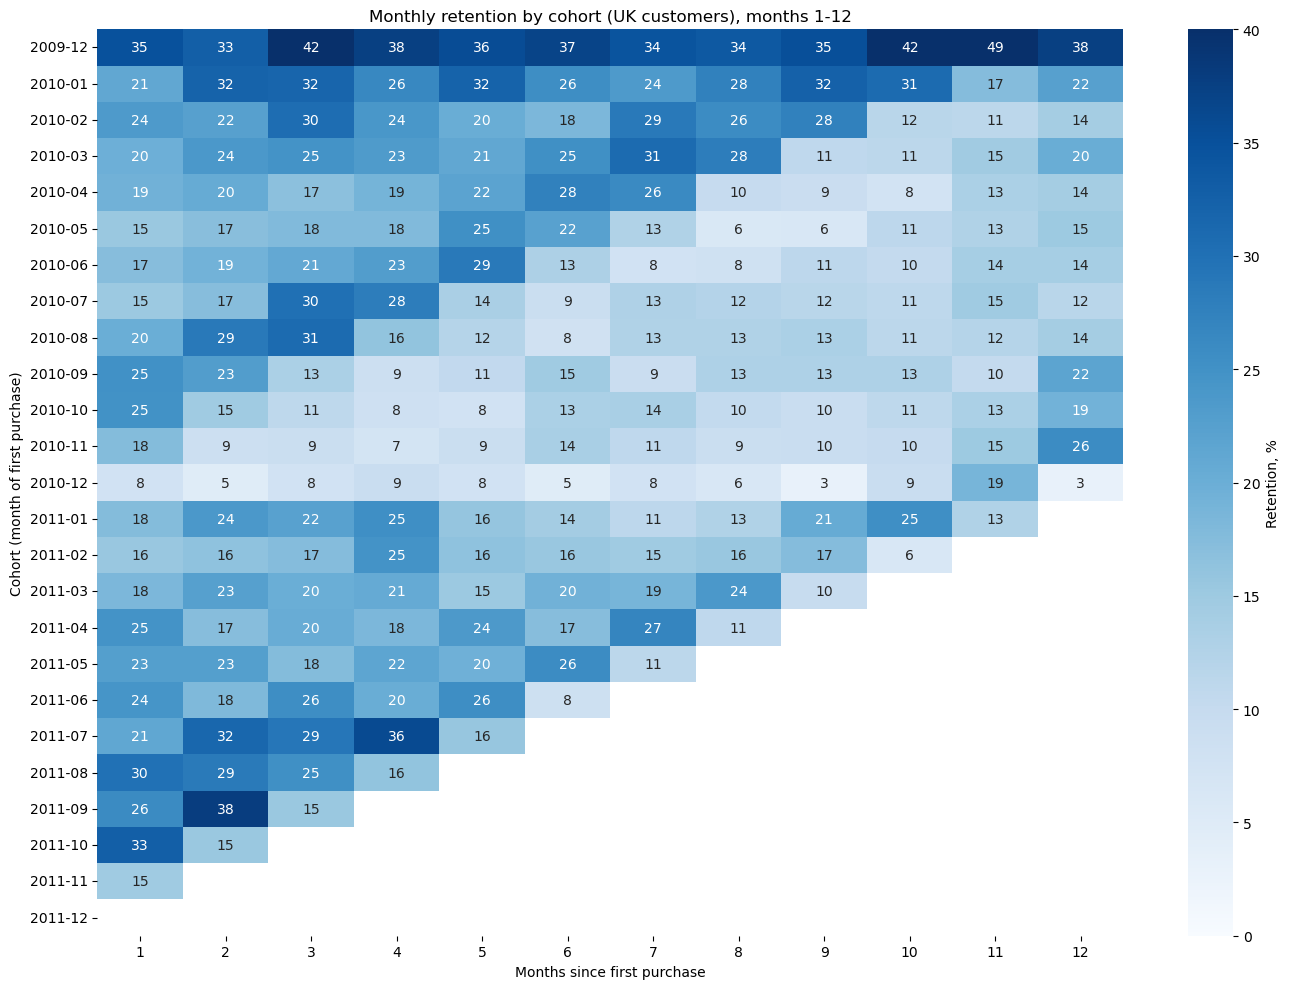

In [107]:
plot_data = retention_matrix.loc[:, 1:12]
plt.figure(figsize=(14, 10))
sns.heatmap(plot_data, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=40,cbar_kws={"label": "Retention, %"})
plt.title("Monthly retention by cohort (UK customers), months 1-12")
plt.xlabel("Months since first purchase")
plt.ylabel("Cohort (month of first purchase)")
plt.tight_layout()
plt.show()

**Heatmap analysis**
1. Only 15-30% of new customers make a purchase in the month after their first order. This confirms the RFM result as the main loss of customers happens between the first and the second order.
2. Retention is strongly seasonal: customers from different cohorts come back in the same months (September-November), which can be seen as dark diagonal lines on the heatmap. Wholesalers stock up for Christmas.
3. Customers who made their first order right before Christmas (Oct-Dec 2010 cohorts) have the lowest retention (3-11%). However, some of them come back next fall.
4. The 2011 cohorts show better retention in month 1 than the 2010 cohorts (21-33% vs 15-20%), but these cohorts are smaller, so the difference may be partly noise.
5. Limitations: the Dec 2009 cohort is biased (it includes old customers, because the data starts in Dec 2009), and the last value of every row is underestimated, because Dec 2011 has only 9 days of data.

# Part 4. Validation: can RFM predict the customers' future behaviour?

The segments are built **only on the first year** (Dec 2009 – Nov 2010, snapshot date 1 Dec 2010) and compared with the revenue of the **second year** (Dec 2010 – Dec 2011). Second-year data is not used to build the segments.

### 4.1 First-year customer table

In [108]:
duckdb.sql("""
create or replace table customers_first_year AS  
select
customer_id,
max(invoice_date) FILTER (WHERE NOT cancel_order) as last_purchase,
count(distinct(invoice)) filter (where not cancel_order) as frequency,
sum(revenue) filter (WHERE NOT delivery_order) as monetary,
DATE_DIFF('day', last_purchase, TIMESTAMP '2010-12-01') as recency_date
from clean_table_df 
WHERE customer_id is not null  
and country='United Kingdom'
and invoice_date < Timestamp '2010-12-01'
GROUP BY customer_id
""")

In [109]:
q("""
select count(*)as n_customers,
sum(case when monetary <= 0 then 1 ELSE 0 END) as non_positive,
sum(case when frequency = 0 then 1 ELSE 0 END) as only_cancels
from customers_first_year
""")

,n_customers,non_positive,only_cancels
0,3940,35.0,27.0


In [110]:
duckdb.sql('delete from customers_first_year where round(monetary,2) <=0')
q('select count(*) from customers_first_year')

,count_star()
0,3902


In [111]:
q("SELECT MIN(recency_date), MAX(recency_date) FROM customers_first_year")

,min(recency_date),max(recency_date)
0,1,365


### 4.2 First-year scores and segments (the same rules as in Part 2)

In [112]:
duckdb.sql("""
create or replace table rfm_first_year as 
select *,
case 
when recency_date <= 30 then 5
when recency_date <= 90 then 4
when recency_date <= 180 then 3
when recency_date <= 365 then 2
else 1
end as recency_score,
case
when frequency = 1 then 1
when frequency = 2 then 2
when frequency between 3 and 4 then 3
when frequency between 5 and 9 then 4
else 5
end as frequency_score,
NTILE(5) over (order by monetary) as monetary_score
FROM customers_first_year
""")

In [113]:
duckdb.sql("""
create or replace table rfm_segments_first_year as
select *,
CASE
when recency_score >= 4 AND frequency_score >= 4 THEN 'Champions'
when recency_score >= 3 AND frequency_score >= 3 THEN 'Loyal'
when recency_score >= 4 AND frequency_score = 1  THEN 'New'
when recency_score >= 3 AND frequency_score = 2  THEN 'Promising'
when recency_score <= 2 AND frequency_score >= 3 THEN 'At risk'
when recency_score = 2  AND frequency_score <= 2 THEN 'Inactive'
when recency_score = 1  AND frequency_score <= 2 THEN 'Churned'
when recency_score = 3 AND frequency_score = 1 THEN 'Need attention'
end as segment
from rfm_first_year
""")

In [114]:
q("select segment, count(*) AS n_clients, round(count(*) * 100.0 / sum(count(*)) over (), 2) as share_clients from rfm_segments_first_year group by segment order by n_clients DESC")

,segment,n_clients,share_clients
0,Champions,960,24.60
1,Loyal,823,21.09
2,Inactive,633,16.22
3,Promising,597,15.30
4,New,594,15.22
5,Need attention,209,5.36
6,At risk,86,2.20


**Limitation of the first-year segments:** the first year has only 365 days of data (Dec 2009 - Nov 2010), so recency cannot be more than 365 days. That is why no customer gets recency_score = 1, and the 'Churned' segment is empty. The 'At risk' segment is also very small (86 vs 688 in part 2): to be 'at risk' a customer needs 3+ orders and then no purchases for 6+ months, so all these orders must be made in the first half of the year.

### 4.3 Second-year revenue

In [115]:
duckdb.sql("""
create or replace table revenue_second_year AS  
select
customer_id,
count(distinct(invoice)) filter (where not cancel_order) as orders_second_year,
sum(revenue) filter (WHERE NOT delivery_order) as monetary_second_year,
from clean_table_df 
WHERE customer_id is not null  
and country='United Kingdom'
and invoice_date >= Timestamp '2010-12-01'
GROUP BY customer_id
""")

In [116]:
q("""select count(*) AS customers, round(SUM(monetary_second_year)) as total_revenue, sum(CASE WHEN orders_second_year = 0 then 1 else 0 end) as cancels
from revenue_second_year""")

,customers,total_revenue,cancels
0,3942,6797517.0,26.0


### 4.4 First-year segments vs second-year behaviour

In [117]:
validation = q("""SELECT s.segment,
COUNT(*) as customers,
round(avg(case when COALESCE(r.orders_second_year, 0) > 0 THEN 1 ELSE 0 END) * 100, 1) as pct_bought_y2,
round(median(coalesce(r.monetary_second_year, 0))) as median_rev_y2,
round(avg(coalesce(r.monetary_second_year, 0))) as avg_rev_y2,
round(sum(r.monetary_second_year) * 100.0 / sum(sum(coalesce(r.monetary_second_year, 0))) over (), 2) as share_rev_y2
FROM rfm_segments_first_year s
left JOIN revenue_second_year r
on s.customer_id=r.customer_id
group by s.segment
order by avg_rev_y2 DESC
""")
validation

,segment,customers,pct_bought_y2,median_rev_y2,avg_rev_y2,share_rev_y2
0,Champions,960,92.6,1876.0,4190.0,72.79
1,Loyal,823,75.6,419.0,920.0,13.70
2,Promising,597,61.5,192.0,514.0,5.55
3,New,594,49.7,0.0,387.0,4.16
4,At risk,86,48.8,0.0,296.0,0.46
5,Inactive,633,32.5,0.0,221.0,2.54
6,Need attention,209,32.5,0.0,209.0,0.79


**Part 4 findings:**
1. The segments built only on the first year predicted the customers' behaviour in the second year: the segments are ordered by the second-year revenue as expected (Champions > Loyal > Promising > New > …).
2. 93% of the first-year champions bought something in the second year and generated 73% of the second-year revenue, although they were only 25% of the customers. The "1/4 of the customers bring 3/4 of the revenue" pattern also holds for the next year.
3. An average champion spent about 20 times more in the second year than an average 'inactive' or 'need attention' customer (£4,190 vs ~£210).
4. For New, At risk, Inactive and Need attention segments the median second-year revenue is £0: more than half of these customers didn't buy anything in the second year. Their average revenue is higher only because of a small group of customers who came back.
5. Limitations: the first-year window is only 12 months, so there is no 'churned' segment and the 'at risk' segment is very small (86 customers), so the conclusions about it are not reliable.

**Conclusion:** the RFM segmentation can be used for planning the marketing budget, because the segments built on one year of data predicted which customers would bring the revenue in the next year. The company should focus on keeping the champions and loyal customers, and on converting new customers into the second order, as most of the lost customers made only one purchase.

# Summary

1. **Data quality:** the raw data had overlapping sheets (22,523 duplicated rows), cancellations, stock write-offs, bad debt adjustments, marketplace fees and test records. Each type was analysed separately and a cleaning rule was defined for it.
2. **RFM segmentation:** 28% of the UK customers (champions) generate 74% of the revenue, while 21% of the customers (churned) generate only 3%. 'At risk' customers represent £1.30M of past revenue; winning back 20% of them could bring ~£130k per year.
3. **Cohort analysis:** only 15–30% of new customers buy again in the next month, and retention is strongly seasonal (customers come back in September–November before Christmas).
4. **Validation:** segments built on the first year predicted the second year: 93% of the first-year champions bought again and generated 73% of the second-year revenue.
5. **Main recommendation:** the biggest loss of customers happens between the first and the second order, so the company should focus on converting new customers into repeat buyers, and on keeping the champions with non-monetary benefits.

# Export for Tableau

In [118]:
q("""
select * replace (cast(customer_id as integer) as customer_id, round(monetary, 2) as monetary)
from rfm_segments
""").to_csv("rfm_segments.csv", index=False)
retention.to_csv("retention.csv", index=False)
validation.to_csv("validation.csv", index=False)